# Transformer Base — Last-Token Pooling

Same base config as `model_training_Transformer_multistep_rolling_origin.ipynb` (d_model=64, 4 heads, ff_dim=128, 2 blocks, dropout=0.1, lr=1e-3, batch=256) -- only architectural change: `GlobalAveragePooling1D` replaced with last-token pooling (`x[:, -1, :]`, via the `LastTokenPooling` layer below), which preserves the input window's most recent timestep instead of averaging over all of them.

Predicts a full day's 24 hourly GHI values from the previous day's 24 hours of weather data.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from numpy.lib.stride_tricks import sliding_window_view
import tensorflow as tf
from tensorflow import keras
import joblib
import time

tf.random.set_seed(42)
np.random.seed(42)

tf.config.experimental.enable_op_determinism()

for _gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(_gpu, True)


I0000 00:00:1788341756.176850  251891 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788341756.213807  251891 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1788341756.994761  251891 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Load data and select features

In [2]:
DATA_PATH = '../../../data/FYP_Cleaned_Dataset.csv'

df = pd.read_csv(DATA_PATH, parse_dates=['Datetime'])
df = df.sort_values(['State', 'Datetime']).reset_index(drop=True)

# lag features, per state, before the split (real deployment always has recent
# real GHI available before predicting the next step -> not leakage)
df['GHI_lag_1h'] = df.groupby('State')['GHI_W_m2'].shift(1)
df['GHI_lag_24h'] = df.groupby('State')['GHI_W_m2'].shift(24)
df = df.dropna(subset=['GHI_lag_1h', 'GHI_lag_24h']).reset_index(drop=True)

# best-known feature set (feature_selection.ipynb + Run 4/8): drop
# Surface_Pressure_kPa, Longitude, Temp_Air_2m_C; add the two GHI lags
FEATURE_COLS = [
    'Latitude', 'Cloud_Coverage_Pct', 'Temp_Skin_C',
    'Relative_Humidity_Pct', 'Wind_Speed_10m_m_s',
    'Precipitable_Water_cm', 'Rainfall_mm_log', 'Is_Daylight',
    'Hour_sin', 'Hour_cos', 'Wind_Sine', 'Wind_Cosine',
    'GHI_lag_1h', 'GHI_lag_24h',
]
TARGET_COL = 'GHI_W_m2'

print(df.shape)
df.head()


(1314000, 20)


,Datetime,State,Latitude,Longitude,GHI_W_m2,Cloud_Coverage_Pct,Temp_Skin_C,Relative_Humidity_Pct,Wind_Speed_10m_m_s,Wind_Direction_10m_deg,Precipitable_Water_cm,Hour,Is_Daylight,Hour_sin,Hour_cos,Wind_Sine,Wind_Cosine,Rainfall_mm_log,GHI_lag_1h,GHI_lag_24h
0,2016-01-03 00:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.83,25.63,94.90,2.74,3.1,5.71,0,0,0.000000,1.000000,0.054079,0.998537,3.442979,0.0,0.0
1,2016-01-03 01:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,100.00,25.54,95.00,2.68,1.7,5.74,1,0,0.258819,0.965926,0.029666,0.999560,3.337192,0.0,0.0
2,2016-01-03 02:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.72,25.47,94.96,2.62,358.9,5.68,2,0,0.500000,0.866025,-0.019197,0.999816,3.377929,0.0,0.0
3,2016-01-03 03:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.68,25.42,94.93,2.60,354.9,5.68,3,0,0.707107,0.707107,-0.088894,0.996041,3.371425,0.0,0.0
4,2016-01-03 04:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.98,25.39,94.82,2.65,350.2,5.67,4,0,0.866025,0.500000,-0.170209,0.985408,3.349904,0.0,0.0


## 2. Split data into train/val/test

In [3]:
TRAIN_FRAC = 0.7
VAL_FRAC = 0.1

def split_state(group):
    n = len(group)
    train_end = int(n * TRAIN_FRAC)
    val_end = int(n * (TRAIN_FRAC + VAL_FRAC))
    return group.iloc[:train_end], group.iloc[train_end:val_end], group.iloc[val_end:]

train_parts, val_parts, test_parts = [], [], []
for state, group in df.groupby('State', sort=False):
    tr, va, te = split_state(group)
    train_parts.append(tr); val_parts.append(va); test_parts.append(te)

train_df = pd.concat(train_parts).reset_index(drop=True)
val_df = pd.concat(val_parts).reset_index(drop=True)
test_df = pd.concat(test_parts).reset_index(drop=True)

print('Train:', train_df.shape, train_df['Datetime'].min(), '-', train_df['Datetime'].max())
print('Val:  ', val_df.shape, val_df['Datetime'].min(), '-', val_df['Datetime'].max())
print('Test: ', test_df.shape, test_df['Datetime'].min(), '-', test_df['Datetime'].max())


Train: (919785, 20) 2016-01-03 00:00:00 - 2022-12-31 22:00:00
Val:   (131415, 20) 2022-12-31 23:00:00 - 2023-12-31 23:00:00
Test:  (262800, 20) 2024-01-01 00:00:00 - 2025-12-30 23:00:00


## 3. Scale features and target

In [4]:
x_scaler = MinMaxScaler(feature_range=(0, 1))
y_scaler = MinMaxScaler(feature_range=(0, 1))

x_scaler.fit(train_df[FEATURE_COLS])
y_scaler.fit(train_df[[TARGET_COL]])

def scale(frame):
    frame = frame.copy()
    frame[FEATURE_COLS] = x_scaler.transform(frame[FEATURE_COLS])
    frame[TARGET_COL + '_scaled'] = y_scaler.transform(frame[[TARGET_COL]])
    return frame

train_scaled = scale(train_df)
val_scaled = scale(val_df)
test_scaled = scale(test_df)


## 4. Build input/output windows

In [5]:
WINDOW_SIZE = 24
OUTPUT_HORIZON = 24
BATCH_SIZE = 256

def build_multistep_dataset(frame, shuffle, stride=1):
    datasets = []
    for _, group in frame.groupby('State', sort=False):
        group = group.sort_values('Datetime')
        n = len(group)
        if n <= WINDOW_SIZE + OUTPUT_HORIZON:
            continue
        X = group[FEATURE_COLS].to_numpy(dtype='float32')
        y = group[TARGET_COL + '_scaled'].to_numpy(dtype='float32')


        X_for_windowing = X[: n - OUTPUT_HORIZON]
        y_for_windowing = y[WINDOW_SIZE:]

        ds_X = keras.utils.timeseries_dataset_from_array(
            data=X_for_windowing, targets=None, sequence_length=WINDOW_SIZE,
            sequence_stride=stride, batch_size=BATCH_SIZE,
        )
        ds_y = keras.utils.timeseries_dataset_from_array(
            data=y_for_windowing, targets=None, sequence_length=OUTPUT_HORIZON,
            sequence_stride=stride, batch_size=BATCH_SIZE,
        )
        datasets.append(tf.data.Dataset.zip((ds_X, ds_y)))

    combined = datasets[0]
    for ds in datasets[1:]:
        combined = combined.concatenate(ds)
    if shuffle:
        combined = combined.shuffle(buffer_size=10_000, seed=42)
    return combined.prefetch(tf.data.AUTOTUNE)

train_ds = build_multistep_dataset(train_scaled, shuffle=True, stride=1)
val_ds = build_multistep_dataset(val_scaled, shuffle=False, stride=1)
test_ds = build_multistep_dataset(test_scaled, shuffle=False, stride=1)

for xb, yb in train_ds.take(1):
    print('Batch X shape:', xb.shape, 'Batch y shape:', yb.shape)


I0000 00:00:1788341759.706510  251891 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


I0000 00:00:1788341772.161617  252085 shuffle_dataset_op.cc:453] ShuffleDatasetV3:359: Filling up shuffle buffer (this may take a while): 1696 of 10000


Batch X shape: (256, 24, 14) Batch y shape: (256, 24)


I0000 00:00:1788341783.633281  252085 shuffle_dataset_op.cc:483] Shuffle buffer filled.


## 5. Define the model (custom Transformer encoder blocks)

In [6]:
D_MODEL = 64
NUM_HEADS = 4
FF_DIM = 128
NUM_ENCODER_BLOCKS = 2
DROPOUT_RATE = 0.1


@keras.utils.register_keras_serializable(package='Transformer')
class PositionalEncoding(keras.layers.Layer):
    """Fixed (non-trainable) sinusoidal positional encoding, added to the input embedding."""

    def __init__(self, sequence_length, d_model, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.d_model = d_model
        self.pos_encoding = self._build_positional_encoding(sequence_length, d_model)

    @staticmethod
    def _build_positional_encoding(sequence_length, d_model):
        position = np.arange(sequence_length)[:, np.newaxis]
        div_term = np.exp(np.arange(0, d_model, 2) * -(np.log(10000.0) / d_model))
        pe = np.zeros((sequence_length, d_model), dtype='float32')
        pe[:, 0::2] = np.sin(position * div_term)
        pe[:, 1::2] = np.cos(position * div_term)
        return tf.constant(pe[np.newaxis, ...], dtype='float32')  # (1, seq_len, d_model)

    def call(self, inputs):
        return inputs + self.pos_encoding

    def get_config(self):
        config = super().get_config()
        config.update({'sequence_length': self.sequence_length, 'd_model': self.d_model})
        return config


@keras.utils.register_keras_serializable(package='Transformer')
class TransformerEncoderBlock(keras.layers.Layer):
    """Standard (Vaswani-style) encoder block: self-attention + feed-forward, each with
    residual connection + LayerNorm, matching the base Transformer encoder design."""

    def __init__(self, d_model, num_heads, ff_dim, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.dropout_rate = dropout_rate

        self.attention = keras.layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=d_model // num_heads
        )
        self.attn_dropout = keras.layers.Dropout(dropout_rate)
        self.attn_norm = keras.layers.LayerNormalization(epsilon=1e-6)

        self.ffn = keras.Sequential([
            keras.layers.Dense(ff_dim, activation='relu'),
            keras.layers.Dense(d_model),
        ])
        self.ffn_dropout = keras.layers.Dropout(dropout_rate)
        self.ffn_norm = keras.layers.LayerNormalization(epsilon=1e-6)

    def build(self, input_shape):
        self.attention.build(input_shape, input_shape)
        self.attn_dropout.build(input_shape)
        self.attn_norm.build(input_shape)
        self.ffn.build(input_shape)
        self.ffn_dropout.build(input_shape)
        self.ffn_norm.build(input_shape)
        super().build(input_shape)

    def call(self, inputs, training=False):
        attn_out = self.attention(query=inputs, value=inputs, key=inputs, training=training)
        attn_out = self.attn_dropout(attn_out, training=training)
        x = self.attn_norm(inputs + attn_out)

        ffn_out = self.ffn(x, training=training)
        ffn_out = self.ffn_dropout(ffn_out, training=training)
        return self.ffn_norm(x + ffn_out)

    def get_config(self):
        config = super().get_config()
        config.update({
            'd_model': self.d_model,
            'num_heads': self.num_heads,
            'ff_dim': self.ff_dim,
            'dropout_rate': self.dropout_rate,
        })
        return config


@keras.utils.register_keras_serializable(package='Transformer')
class LastTokenPooling(keras.layers.Layer):
    """Takes the encoder's output at the last input timestep only, instead
    of averaging across all timesteps."""

    def call(self, inputs):
        return inputs[:, -1, :]


n_features = len(FEATURE_COLS)

inputs = keras.layers.Input(shape=(WINDOW_SIZE, n_features))
x = keras.layers.Dense(D_MODEL)(inputs)  # project raw features to d_model
x = PositionalEncoding(WINDOW_SIZE, D_MODEL)(x)
for _ in range(NUM_ENCODER_BLOCKS):
    x = TransformerEncoderBlock(D_MODEL, NUM_HEADS, FF_DIM, DROPOUT_RATE)(x)
x = LastTokenPooling()(x)  # Fix 1: was GlobalAveragePooling1D()(x)
x = keras.layers.Dense(16, activation='relu')(x)
outputs = keras.layers.Dense(OUTPUT_HORIZON)(x)  # direct 24h-ahead output, no recursion

model = keras.Model(inputs, outputs, name='ghi_transformer_multistep')

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='mse', metrics=['mae'])
model.summary()


Model: "ghi_transformer_multistep"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 24, 14)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24, 64)         │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_encoding             │ (None, 24, 64)         │             0 │
│ (PositionalEncoding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_block       │ (None, 24, 64)         │        33,472 │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_block_1     │ (None, 24, 64)         │        33,472 │
│ (TransformerEncoderBlock)       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_token_pooling              │ (None, 64)             │             0 │
│ (LastTokenPooling)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 24)             │           408 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,352 (270.91 KB)

 Trainable params: 69,352 (270.91 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the model

In [7]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5),
]

train_start = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=callbacks)
train_duration_sec = time.time() - train_start

best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print(f'Training time: {train_duration_sec/60:.2f} min, best epoch {best_epoch}/{len(history.history["val_loss"])}')

Epoch 1/50


/home/kelocker/miniconda3/envs/fyp/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


I0000 00:00:1788341796.778534  252170 shuffle_dataset_op.cc:453] ShuffleDatasetV3:359: Filling up shuffle buffer (this may take a while): 1381 of 10000


I0000 00:00:1788341806.781911  252170 shuffle_dataset_op.cc:453] ShuffleDatasetV3:359: Filling up shuffle buffer (this may take a while): 2670 of 10000


I0000 00:00:1788341813.841445  252170 shuffle_dataset_op.cc:483] Shuffle buffer filled.


   1/3600 ━━━━━━━━━━━━━━━━━━━━ 30:36:38 31s/step - loss: 0.6135 - mae: 0.6367

... (29,683 outputs left out)

3595/3600 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0043 - mae: 0.0420

3598/3600 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0043 - mae: 0.0420

3600/3600 ━━━━━━━━━━━━━━━━━━━━ 121s 25ms/step - loss: 0.0043 - mae: 0.0420 - val_loss: 0.0043 - val_mae: 0.0417 - learning_rate: 1.2500e-04


Training time: 46.34 min, best epoch 18/23


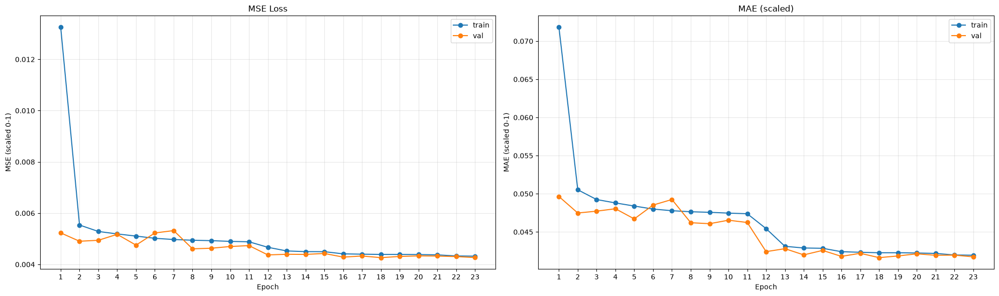

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

epochs = range(1, len(history.history['loss']) + 1)

axes[0].plot(epochs, history.history['loss'], label='train', marker='o')
axes[0].plot(epochs, history.history['val_loss'], label='val', marker='o')
axes[0].set_title('MSE Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE (scaled 0-1)')
axes[0].set_xticks(list(epochs))
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(epochs, history.history['mae'], label='train', marker='o')
axes[1].plot(epochs, history.history['val_mae'], label='val', marker='o')
axes[1].set_title('MAE (scaled)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE (scaled 0-1)')
axes[1].set_xticks(list(epochs))
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## 6b. Validation evaluation (real units)

In [9]:
# Evaluate on the validation set in real W/m² units

y_true_val_scaled = np.concatenate([y.numpy() for _, y in val_ds], axis=0)
y_pred_val_scaled = model.predict(val_ds)

y_true_val = y_scaler.inverse_transform(y_true_val_scaled.reshape(-1, 1)).reshape(y_true_val_scaled.shape)
y_pred_val = y_scaler.inverse_transform(y_pred_val_scaled.reshape(-1, 1)).reshape(y_pred_val_scaled.shape)
y_pred_val = np.clip(y_pred_val, 0, None)

val_mae = mean_absolute_error(y_true_val.flatten(), y_pred_val.flatten())
val_rmse = np.sqrt(mean_squared_error(y_true_val.flatten(), y_pred_val.flatten()))
val_r2 = r2_score(y_true_val.flatten(), y_pred_val.flatten())
val_mbe = float(np.mean(y_pred_val.flatten() - y_true_val.flatten()))
val_nrmse = val_rmse / np.mean(y_true_val.flatten()) * 100
print(f'Validation (all origins, all horizons pooled) MAE: {val_mae:.4f}  RMSE: {val_rmse:.4f}  '
      f'R2: {val_r2:.4f}  MBE: {val_mbe:.4f}  nRMSE: {val_nrmse:.2f}%  (W/m²)')


  1/525 ━━━━━━━━━━━━━━━━━━━━ 1:56 223ms/step

  5/525 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step   

  9/525 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step

 14/525 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step

 19/525 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step

 25/525 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step

... (88 outputs left out)

518/525 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

524/525 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

525/525 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step


Validation (all origins, all horizons pooled) MAE: 38.2922  RMSE: 67.8310  R2: 0.9387  MBE: 6.0878  nRMSE: 33.48%  (W/m²)


## 7. Standard test evaluation (all stride-1 origins, real W/m² units)

In [10]:
y_true_scaled = np.concatenate([y.numpy() for _, y in test_ds], axis=0)  # (n, 24)
y_pred_scaled = model.predict(test_ds)  # (n, 24)

y_true = y_scaler.inverse_transform(y_true_scaled.reshape(-1, 1)).reshape(y_true_scaled.shape)
y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(y_pred_scaled.shape)
y_pred = np.clip(y_pred, 0, None)

mae = mean_absolute_error(y_true.flatten(), y_pred.flatten())
rmse = np.sqrt(mean_squared_error(y_true.flatten(), y_pred.flatten()))
r2 = r2_score(y_true.flatten(), y_pred.flatten())
mbe = float(np.mean(y_pred.flatten() - y_true.flatten()))
nrmse = rmse / np.mean(y_true.flatten()) * 100
print(f'Test (all origins, all horizons pooled) MAE: {mae:.4f}  RMSE: {rmse:.4f}  R2: {r2:.4f}  MBE: {mbe:.4f}  nRMSE: {nrmse:.2f}%  (W/m²)')

test_horizon_rows = []
for h in range(OUTPUT_HORIZON):
    yt, yp = y_true[:, h], y_pred[:, h]
    test_horizon_rows.append({
        'horizon_h': h + 1,
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
test_horizon_df = pd.DataFrame(test_horizon_rows)
test_horizon_df


   1/1035 ━━━━━━━━━━━━━━━━━━━━ 49s 48ms/step

   5/1035 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step

  10/1035 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step

  15/1035 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step

  21/1035 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step

  25/1035 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step

... (177 outputs left out)

1031/1035 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

1035/1035 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step


Test (all origins, all horizons pooled) MAE: 39.0794  RMSE: 69.3781  R2: 0.9361  MBE: 5.9275  nRMSE: 34.17%  (W/m²)


,horizon_h,mae,rmse,r2
0,1,27.581450,46.278051,0.971555
1,2,28.225929,49.992651,0.966805
2,3,32.598316,56.983546,0.956873
3,4,37.249985,62.588894,0.947971
4,5,38.243462,64.790441,0.944246
5,6,37.242985,66.238719,0.941726
6,7,38.332211,68.442701,0.937783
7,8,40.639809,70.216723,0.934514
8,9,40.652168,70.392739,0.934186
9,10,38.773521,70.137630,0.934667


In [11]:
# persistence baseline: D+1 hour h = D hour h ("tomorrow looks like today"),
# same stride-1 windowing as the model's test set above so it's apples-to-apples
baseline_true_parts, baseline_pred_parts = [], []
for _, group in test_df.groupby('State', sort=False):
    group = group.sort_values('Datetime')
    values = group[TARGET_COL].to_numpy()
    n = len(values)
    if n <= WINDOW_SIZE + OUTPUT_HORIZON:
        continue
    windows = sliding_window_view(values, WINDOW_SIZE + OUTPUT_HORIZON)
    baseline_pred_parts.append(windows[:, :WINDOW_SIZE])
    baseline_true_parts.append(windows[:, WINDOW_SIZE:])

baseline_true = np.concatenate(baseline_true_parts).flatten()
baseline_pred = np.concatenate(baseline_pred_parts).flatten()
baseline_mae = mean_absolute_error(baseline_true, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(baseline_true, baseline_pred))

print(f'Persistence (D+1 = D) baseline MAE: {baseline_mae:.4f}  RMSE: {baseline_rmse:.4f}')
print(f'Improvement over baseline: MAE {(baseline_mae-mae)/baseline_mae*100:.2f}%  RMSE {(baseline_rmse-rmse)/baseline_rmse*100:.2f}%')


Persistence (D+1 = D) baseline MAE: 43.7061  RMSE: 94.1654
Improvement over baseline: MAE 10.59%  RMSE 26.32%


## 7b. Plot predicted vs actual, pooled across all 15 states (validation + test period)

E0000 00:00:1788344596.854947  251891 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


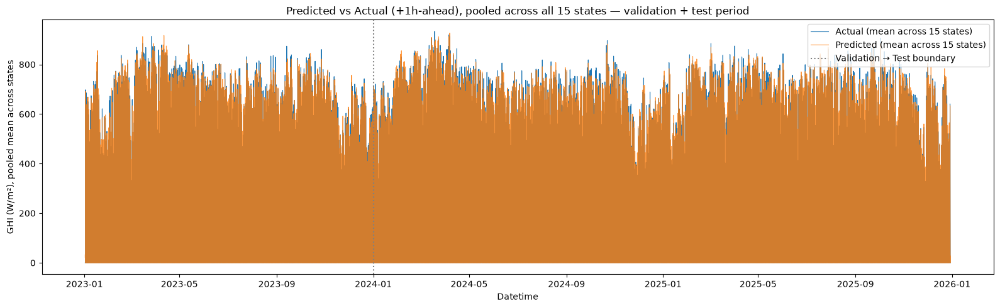

In [12]:
# Build the model's +1h-ahead prediction vs actual for every state,
# across the validation + test period, then average across all 15
# states at each timestamp -- one pooled overview.

valtest_scaled = pd.concat([val_scaled, test_scaled]).sort_values(['State', 'Datetime'])
states = sorted(valtest_scaled["State"].unique())

per_state_series = []
for state in states:
    state_data = valtest_scaled[valtest_scaled['State'] == state].sort_values('Datetime')
    X_state = state_data[FEATURE_COLS].to_numpy(dtype='float32')
    actual_state = state_data[TARGET_COL].to_numpy(dtype='float32')
    dt_state = state_data['Datetime'].to_numpy()

    n = len(X_state)
    if n <= WINDOW_SIZE + OUTPUT_HORIZON:
        continue

    n_windows = n - WINDOW_SIZE - OUTPUT_HORIZON + 1
    Xw = sliding_window_view(X_state[: n - OUTPUT_HORIZON], WINDOW_SIZE, axis=0)[:n_windows]
    Xw = Xw.transpose(0, 2, 1)  # (n_windows, WINDOW_SIZE, n_features) -- Transformer needs 3D, not flattened

    pred_scaled = model.predict(Xw, batch_size=4096, verbose=0)[:, 0]  # +1h-ahead column only
    pred = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
    pred = np.clip(pred, 0, None)

    actual = actual_state[WINDOW_SIZE: WINDOW_SIZE + n_windows]
    dt_plot = dt_state[WINDOW_SIZE: WINDOW_SIZE + n_windows]

    per_state_series.append(pd.DataFrame({'Datetime': dt_plot, 'actual': actual, 'predicted': pred}))

pooled = pd.concat(per_state_series).groupby('Datetime', as_index=False).mean()
pooled = pooled.sort_values('Datetime')

plt.figure(figsize=(16, 5))
plt.plot(pooled['Datetime'], pooled['actual'], label='Actual (mean across 15 states)', linewidth=0.8)
plt.plot(pooled['Datetime'], pooled['predicted'], label='Predicted (mean across 15 states)', alpha=0.8, linewidth=0.8)
plt.axvline(test_df['Datetime'].min(), color='gray', linestyle=':', label='Validation → Test boundary')
plt.xlabel('Datetime')
plt.ylabel('GHI (W/m²), pooled mean across states')
plt.title('Predicted vs Actual (+1h-ahead), pooled across all 15 states — validation + test period')
plt.legend()
plt.tight_layout()
plt.show()


## 7c. Same plot, zoomed to one month

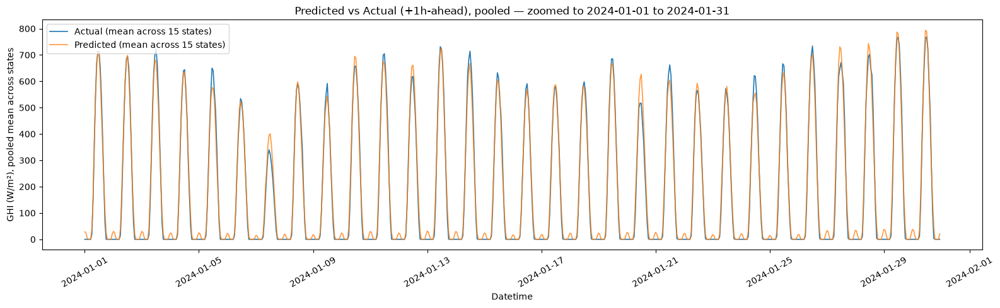

In [13]:
zoom_start = test_df["Datetime"].min()
zoom_end = zoom_start + pd.Timedelta(days=30)
zoomed = pooled[(pooled["Datetime"] >= zoom_start) & (pooled["Datetime"] < zoom_end)]

plt.figure(figsize=(16, 5))
plt.plot(zoomed["Datetime"], zoomed["actual"], label="Actual (mean across 15 states)", linewidth=1.2)
plt.plot(zoomed["Datetime"], zoomed["predicted"], label="Predicted (mean across 15 states)", alpha=0.8, linewidth=1.2)
plt.xlabel("Datetime")
plt.ylabel("GHI (W/m²), pooled mean across states")
plt.title(f"Predicted vs Actual (+1h-ahead), pooled — zoomed to {zoom_start.date()} to {zoom_end.date()}")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 8. Save model & scalers

In [14]:
model.save('ghi_transformer_lasttoken_model.keras')
joblib.dump(x_scaler, 'transformer_lasttoken_x_scaler.joblib')
joblib.dump(y_scaler, 'transformer_lasttoken_y_scaler.joblib')
print('saved.')

saved.


## 9. Rolling-origin evaluation (real day D -> predict real day D+1)

In [15]:
# per-state raw (unscaled) arrays, test period only, using `df` (has correct
# lag features computed on the full un-split timeline)
TEST_START = test_df['Datetime'].min()

state_arrays = {}
for state, g in df.groupby('State', sort=False):
    g = g.sort_values('Datetime')
    g = g[g['Datetime'] >= TEST_START].reset_index(drop=True)
    state_arrays[state] = {
        'dt': g['Datetime'].to_numpy(),
        'X': g[FEATURE_COLS].to_numpy(dtype='float32'),
        'y': g[TARGET_COL].to_numpy(dtype='float32'),
    }

origin_windows, y_true_next_day, origin_meta = [], [], []

for state, arr in state_arrays.items():
    dt, X, y = arr['dt'], arr['X'], arr['y']
    n = len(dt)
    midnight_idx = np.where(pd.DatetimeIndex(dt).hour == 0)[0]  # candidate day-starts D
    for p in midnight_idx:
        if p + 2 * WINDOW_SIZE > n:
            continue  # need D's 24h + D+1's 24h both present
        origin_windows.append(X[p:p + WINDOW_SIZE])                        # D: real 24h window
        y_true_next_day.append(y[p + WINDOW_SIZE:p + 2 * WINDOW_SIZE])     # D+1: real GHI
        origin_meta.append((state, dt[p]))

origin_windows = np.stack(origin_windows)      # (n_origins, 24, n_features)
y_true_next_day = np.stack(y_true_next_day)    # (n_origins, 24)

print(f'{len(origin_meta)} origins across {len(state_arrays)} states')


10935 origins across 15 states


In [16]:
def scale_X(batch):  # (n, 24, n_features) raw -> scaled, same shape
    flat = batch.reshape(-1, len(FEATURE_COLS))
    return x_scaler.transform(flat).reshape(batch.shape).astype('float32')

# single forward pass -- no recursive loop needed, the whole day comes out at once
pred_scaled = model.predict(scale_X(origin_windows), batch_size=4096, verbose=0)
y_pred_next_day = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).reshape(pred_scaled.shape)
y_pred_next_day = np.clip(y_pred_next_day, 0, None)

print('direct rollout done (single forward pass, no recursion):', y_pred_next_day.shape)


direct rollout done (single forward pass, no recursion): (10935, 24)


/home/kelocker/miniconda3/envs/fyp/lib/python3.11/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
E0000 00:00:1788344601.859873  251891 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


In [17]:
y_true_flat = y_true_next_day.flatten()
y_pred_flat = y_pred_next_day.flatten()

mae = mean_absolute_error(y_true_flat, y_pred_flat)
rmse = np.sqrt(mean_squared_error(y_true_flat, y_pred_flat))
r2 = r2_score(y_true_flat, y_pred_flat)
mbe = float(np.mean(y_pred_flat - y_true_flat))
nrmse = rmse / np.mean(y_true_flat) * 100

print(f'Rolling-origin overall (all horizons pooled):')
print(f'  MAE:   {mae:.4f}')
print(f'  RMSE:  {rmse:.4f}')
print(f'  R2:    {r2:.4f}')
print(f'  MBE:   {mbe:.4f}')
print(f'  nRMSE: {nrmse:.2f}%')

horizon_rows = []
for h in range(WINDOW_SIZE):
    yt, yp = y_true_next_day[:, h], y_pred_next_day[:, h]
    horizon_rows.append({
        'horizon_h': h + 1,
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
horizon_df = pd.DataFrame(horizon_rows)
horizon_df


Rolling-origin overall (all horizons pooled):
  MAE:   41.2411
  RMSE:  72.1140
  R2:    0.9309
  MBE:   8.6693
  nRMSE: 35.52%


,horizon_h,mae,rmse,r2
0,1,29.488104,30.765140,0.000000
1,2,15.263491,15.804562,0.000000
2,3,0.020233,0.260085,0.000000
3,4,0.001713,0.116932,0.000000
4,5,0.000734,0.076733,0.000000
5,6,2.368464,6.042448,-13.821733
6,7,45.711185,48.285166,-3.113154
7,8,43.244492,53.904749,0.154604
8,9,63.263584,81.413966,0.349023
9,10,85.977478,108.596551,0.287401


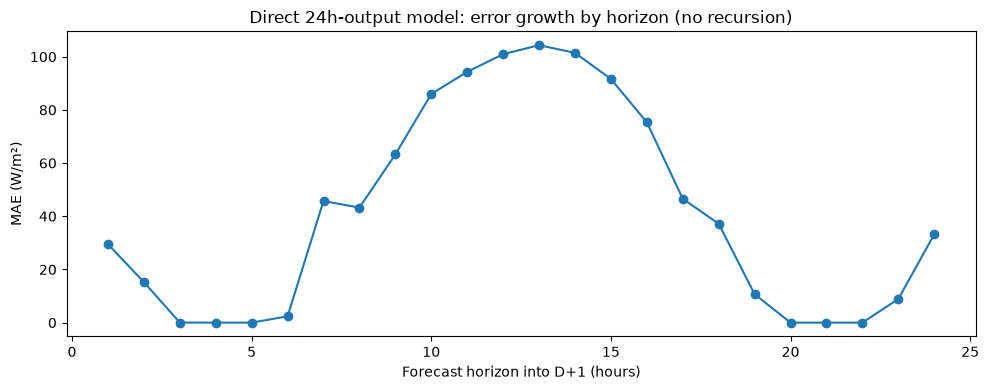

In [18]:
plt.figure(figsize=(10, 4))
plt.plot(horizon_df['horizon_h'], horizon_df['mae'], marker='o')
plt.xlabel('Forecast horizon into D+1 (hours)')
plt.ylabel('MAE (W/m²)')
plt.title('Direct 24h-output model: error growth by horizon (no recursion)')
plt.tight_layout(); plt.show()


In [19]:
# per-state breakdown, so the pooled number isn't hiding a bad state
state_of_origin = np.array([m[0] for m in origin_meta])
per_state_rows = []
for state in sorted(set(state_of_origin)):
    mask = state_of_origin == state
    yt = y_true_next_day[mask].flatten()
    yp = y_pred_next_day[mask].flatten()
    per_state_rows.append({
        'state': state, 'n_origins': int(mask.sum()),
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
per_state_df = pd.DataFrame(per_state_rows)
per_state_df


,state,n_origins,mae,rmse,r2
0,Johor (Johor Bahru),729,47.113564,84.095805,0.895940
1,Kedah (Alor Setar),729,39.807625,69.495268,0.936920
2,Kelantan (Kota Bharu),729,44.341667,78.800579,0.925510
3,Kuala Lumpur,729,37.876312,65.147564,0.938827
4,Melaka (Bandar Melaka),729,39.638332,68.437257,0.932586
5,Negeri Sembilan (Seremban),729,43.422050,74.710499,0.928374
6,Pahang (Kuantan),729,43.195381,76.823500,0.923469
7,Penang (George Town),729,41.216728,70.935944,0.937606
8,Perak (Ipoh),729,36.790279,62.177710,0.946470
9,Perlis (Kangar),729,39.895031,69.340046,0.937202


## 9b. Actual vs. predicted, one concrete forecast example

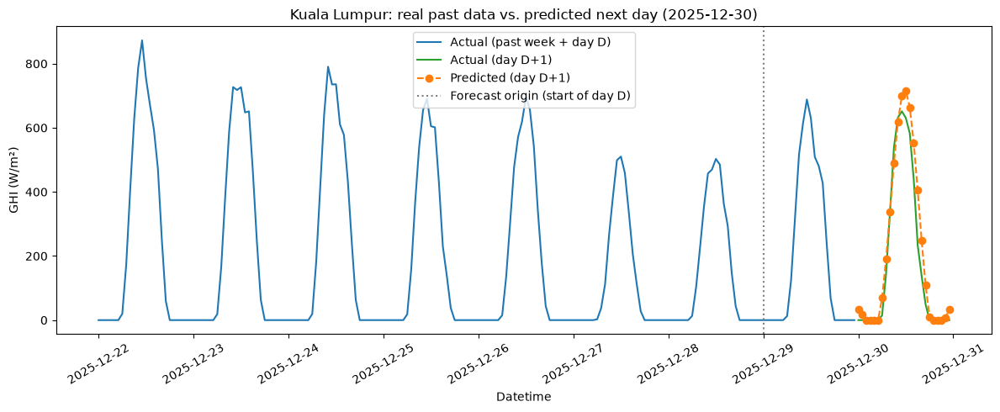

In [20]:
EXAMPLE_STATE = 'Kuala Lumpur'
N_PAST_DAYS = 7

example_indices = [i for i, m in enumerate(origin_meta) if m[0] == EXAMPLE_STATE]
example_idx = example_indices[-1]

arr = state_arrays[EXAMPLE_STATE]
origin_dt = origin_meta[example_idx][1]
origin_pos = np.where(arr['dt'] == origin_dt)[0][0]

past_start = max(0, origin_pos - N_PAST_DAYS * WINDOW_SIZE)
past_dt = arr['dt'][past_start:origin_pos + WINDOW_SIZE]
past_actual = arr['y'][past_start:origin_pos + WINDOW_SIZE]

next_day_dt = arr['dt'][origin_pos + WINDOW_SIZE:origin_pos + 2 * WINDOW_SIZE]
next_day_actual = y_true_next_day[example_idx]
next_day_pred = y_pred_next_day[example_idx]

plt.figure(figsize=(12, 5))
plt.plot(past_dt, past_actual, color='tab:blue', label='Actual (past week + day D)')
plt.plot(next_day_dt, next_day_actual, color='tab:green', label='Actual (day D+1)')
plt.plot(next_day_dt, next_day_pred, color='tab:orange', linestyle='--', marker='o', label='Predicted (day D+1)')
plt.axvline(arr['dt'][origin_pos], color='gray', linestyle=':', label='Forecast origin (start of day D)')
plt.xlabel('Datetime')
plt.ylabel('GHI (W/m²)')
plt.title(f'{EXAMPLE_STATE}: real past data vs. predicted next day ({pd.Timestamp(next_day_dt[0]).date()})')
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [21]:
horizon_df.to_csv('rolling_origin_direct_by_horizon.csv', index=False)
per_state_df.to_csv('rolling_origin_direct_by_state.csv', index=False)
print('saved rolling_origin_direct_by_horizon.csv, rolling_origin_direct_by_state.csv')


saved rolling_origin_direct_by_horizon.csv, rolling_origin_direct_by_state.csv


## 10. Comparison: Transformer vs. LSTM multistep results

In [22]:
# LSTM numbers below are the sibling folder's already-executed output
# (rolling_origin_eval/model_training_LSTM_multistep_rolling_origin.ipynb,
# sections 7/9) -- hardcoded here rather than recomputed, since reproducing
# them needs that notebook's own trained model, not just its saved CSVs.
LSTM_RECURSIVE_MAE, LSTM_RECURSIVE_RMSE, LSTM_RECURSIVE_R2 = 40.9478, 75.4799, 0.9243
LSTM_DIRECT_TEST_MAE, LSTM_DIRECT_TEST_RMSE, LSTM_DIRECT_TEST_R2 = 34.3990, 67.4001, 0.9397
LSTM_DIRECT_ROLLOUT_MAE, LSTM_DIRECT_ROLLOUT_RMSE, LSTM_DIRECT_ROLLOUT_R2 = 35.5148, 69.7478, 0.9354

direct_mae = mean_absolute_error(y_true_flat, y_pred_flat)
direct_rmse = np.sqrt(mean_squared_error(y_true_flat, y_pred_flat))
direct_r2 = r2_score(y_true_flat, y_pred_flat)

print('Rolling-origin, D real -> predict entire D+1, pooled over all 24 horizons:')
print(f'  LSTM recursive rollout (Dense(1) looped 24x, uses D+1 weather):       '
      f'MAE {LSTM_RECURSIVE_MAE:.4f}  RMSE {LSTM_RECURSIVE_RMSE:.4f}  R2 {LSTM_RECURSIVE_R2:.4f}')
print(f'  LSTM direct Dense(24) (standard test set, all origins pooled):        '
      f'MAE {LSTM_DIRECT_TEST_MAE:.4f}  RMSE {LSTM_DIRECT_TEST_RMSE:.4f}  R2 {LSTM_DIRECT_TEST_R2:.4f}')
print(f'  LSTM direct Dense(24) (rolling-origin, midnight-anchored, this eval): '
      f'MAE {LSTM_DIRECT_ROLLOUT_MAE:.4f}  RMSE {LSTM_DIRECT_ROLLOUT_RMSE:.4f}  R2 {LSTM_DIRECT_ROLLOUT_R2:.4f}')
print(f'  Transformer direct Dense(24) (this notebook, rolling-origin):         '
      f'MAE {direct_mae:.4f}  RMSE {direct_rmse:.4f}  R2 {direct_r2:.4f}')


Rolling-origin, D real -> predict entire D+1, pooled over all 24 horizons:
  LSTM recursive rollout (Dense(1) looped 24x, uses D+1 weather):       MAE 40.9478  RMSE 75.4799  R2 0.9243
  LSTM direct Dense(24) (standard test set, all origins pooled):        MAE 34.3990  RMSE 67.4001  R2 0.9397
  LSTM direct Dense(24) (rolling-origin, midnight-anchored, this eval): MAE 35.5148  RMSE 69.7478  R2 0.9354
  Transformer direct Dense(24) (this notebook, rolling-origin):         MAE 41.2411  RMSE 72.1140  R2 0.9309
